# Extraction of spectra
`author` Julien Morin <julien.morin@umontpellier.fr>

`date` 18 Oct 2023

References: *Handbook of CCD Astronomy* §6 ; *Handbook of Astronomical Spectroscopy* §6
* compute master wavelength calibration file
* calibrate science frame
* extract stellar and calibration spectra
* save spectra as FITS files

In [1]:
# import and settings
%matplotlib notebook
import copy
import os
import matplotlib.pyplot as plt
import numpy as np
import scipy.ndimage
import astropy.io.fits as pf
from astropy.stats import mad_std
from astropy import units as u
from astropy.visualization import ZScaleInterval
import ccdproc as ccdp

## Load previously computed data 

In [2]:
# define CCD characteristics
ccd_gain = 0.37 * u.electron / u.adu
ccd_ron = 6.0 * u.electron

In [3]:
# load master bias and print stats
master_bias = ccdp.CCDData.read('reference/master_bias.fits', unit='adu')

INFO: using the unit adu passed to the FITS reader instead of the unit adu in the FITS file. [astropy.nddata.ccddata]


Set MJD-END to 58646.925359 from DATE-END'. [astropy.wcs.wcs]


In [4]:
# load master dark and print info and stats
master_dark30 = ccdp.CCDData.read('reference/master_dark30.fits', unit='adu')
hdu_master_dark30 = master_dark30.to_hdu()
hdu_master_dark30.info()

INFO: using the unit adu passed to the FITS reader instead of the unit adu in the FITS file. [astropy.nddata.ccddata]
Filename: (No file associated with this HDUList)
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      29   (1392, 1040)   float64   
  1  MASK          1 ImageHDU         8   (1392, 1040)   uint8   
  2  UNCERT        1 ImageHDU         9   (1392, 1040)   float64   


Set MJD-END to 58646.926227 from DATE-END'. [astropy.wcs.wcs]


In [5]:
# load master flat and print stats
master_flat = ccdp.CCDData.read('reference/master_flat.fits', unit='adu')

INFO: using the unit adu passed to the FITS reader instead of the unit adu in the FITS file. [astropy.nddata.ccddata]


Set MJD-END to 58646.932535 from DATE-END'. [astropy.wcs.wcs]


## Compute master NeAr

In [6]:
# create wavelength calibration frame collection and print properties
ifc_cal = ccdp.ImageFileCollection('calib/', glob_include='Lune_Calibration_*.fit*')
print(ifc_cal.summary['file', 'date-obs', 'objname', 'exptime'])

                   file                          date-obs      objname exptime
------------------------------------------ ------------------- ------- -------
Lune_Calibration_60s_20190613_002814-1.fit 2019-06-12T22:28:14    Lune      60
Lune_Calibration_60s_20190613_002814-2.fit 2019-06-12T22:29:15    Lune      60
Lune_Calibration_60s_20190613_002814-3.fit 2019-06-12T22:30:15    Lune      60


In [7]:
# compute master calibration 
# this time we use combine w/ arguments set for sigma-clipping rejection
master_cal = ccdp.combine(ifc_cal.files_filtered(include_path=True), unit='adu', combine='average', 
    sigma_clip=True, sigma_clip_low_thresh=7., sigma_clip_high_thresh=7., sigma_clip_func=np.ma.median, sigma_clip_dev_func=mad_std,
    mem_limit=512.e6)

Set MJD-END to 58646.936968 from DATE-END'. [astropy.wcs.wcs]
Set MJD-END to 58646.936968 from DATE-END'.
Set MJD-END to 58646.937674 from DATE-END'. [astropy.wcs.wcs]
Set MJD-END to 58646.937674 from DATE-END'.
Set MJD-END to 58646.938368 from DATE-END'. [astropy.wcs.wcs]
Set MJD-END to 58646.938368 from DATE-END'.


In [8]:
# set header keyword (will appear in the saved file)
master_cal.meta['COMBINED'] = True

In [9]:
### Further work: compare statiscal properties of the series and the master frame

In [10]:
# bias subtract the master cal and print statistics
master_cal_b = ccdp.subtract_bias(master_cal, master_bias)

In [11]:
### Further work: remove hot pixels using the hp pixel mask
###               compare stats before/after correction

## Calibrate science frame

In [12]:
fname_sci = 'Tetha LEO_Object_10s_20190612_233400-1.fit'
ccd_sci = ccdp.CCDData.read('raw/'+fname_sci, unit='adu')

Set MJD-END to 58646.898727 from DATE-END'. [astropy.wcs.wcs]
Set MJD-END to 58646.898727 from DATE-END'.


In [13]:
# bias subtract the master cal and print statistics
ccd_sci_b = ccdp.subtract_bias(ccd_sci, master_bias)

<IPython.core.display.Javascript object>


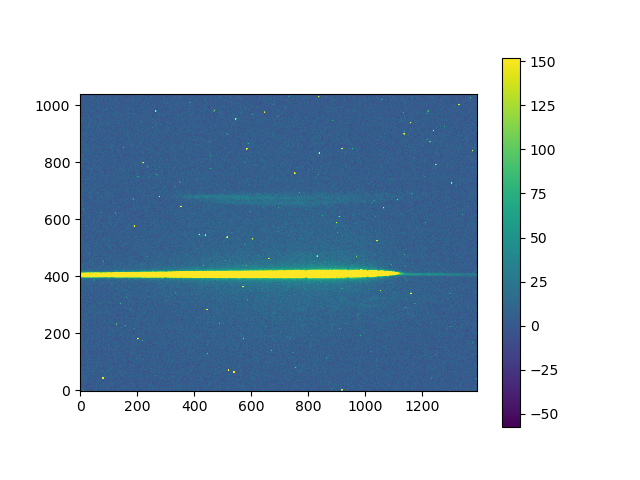

In [14]:
fig = plt.figure()
interval = ZScaleInterval()
z1, z2 = interval.get_limits(ccd_sci_b)
im = plt.imshow(ccd_sci_b, origin='lower', vmin=z1, vmax=z2)
fig.colorbar(im)
plt.show()

In [15]:
### Further work: remove hot pixels using the hp pixel mask
###               compare stats before/after correction

In [16]:
ccd_sci_bg = ccdp.gain_correct(ccd_sci_b, ccd_gain)
npix = ccd_sci_bg.shape[0]*ccd_sci_bg.shape[1]
print('npix    mean    median  std   unit')
print('----------------------------------')
print("%7d %5.2f   %5.2f  %5.2f %s" % (npix, np.mean(ccd_sci_bg.data), np.median(ccd_sci_bg.data), np.std(ccd_sci_bg.data), ccd_sci_bg.unit))

npix    mean    median  std   unit
----------------------------------
1447680 25.37    2.66  292.14 electron


## Define spectral trace

1040 x 1392 pix
696


<IPython.core.display.Javascript object>


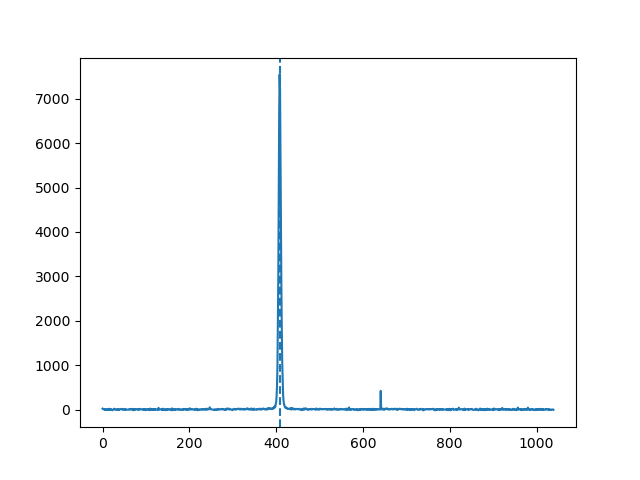

In [17]:
# Plot cut a cut through the image at the central column j0
print("%d x %d pix" % (ccd_sci_bg.shape[0], ccd_sci_bg.shape[1]))
j0 = int(ccd_sci_bg.shape[1]/2)
print(j0)
fig = plt.figure()
plt.plot(ccd_sci_bg.data[:,j0])
# we identify that line i0 corresponds to the peak luminosity
i0 = 408
plt.axvline(i0, ls='--')
plt.show()

<IPython.core.display.Javascript object>


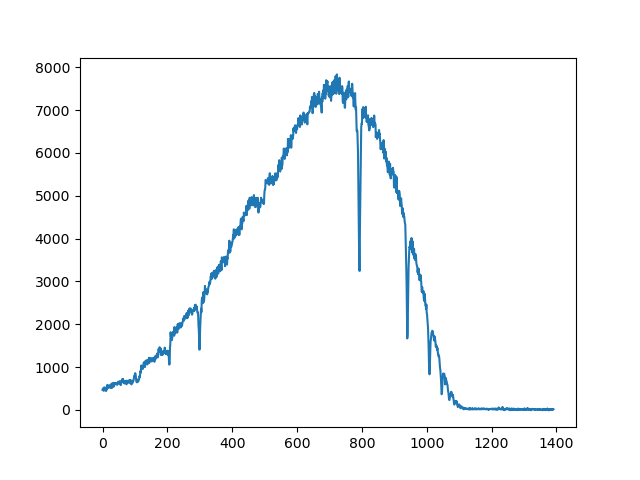

In [18]:
# simplest approach: use spectrum at the line identified above
sci_spec1 = ccd_sci_bg.data[i0,:]
plt.figure()
plt.plot(sci_spec1)
plt.show()

<IPython.core.display.Javascript object>


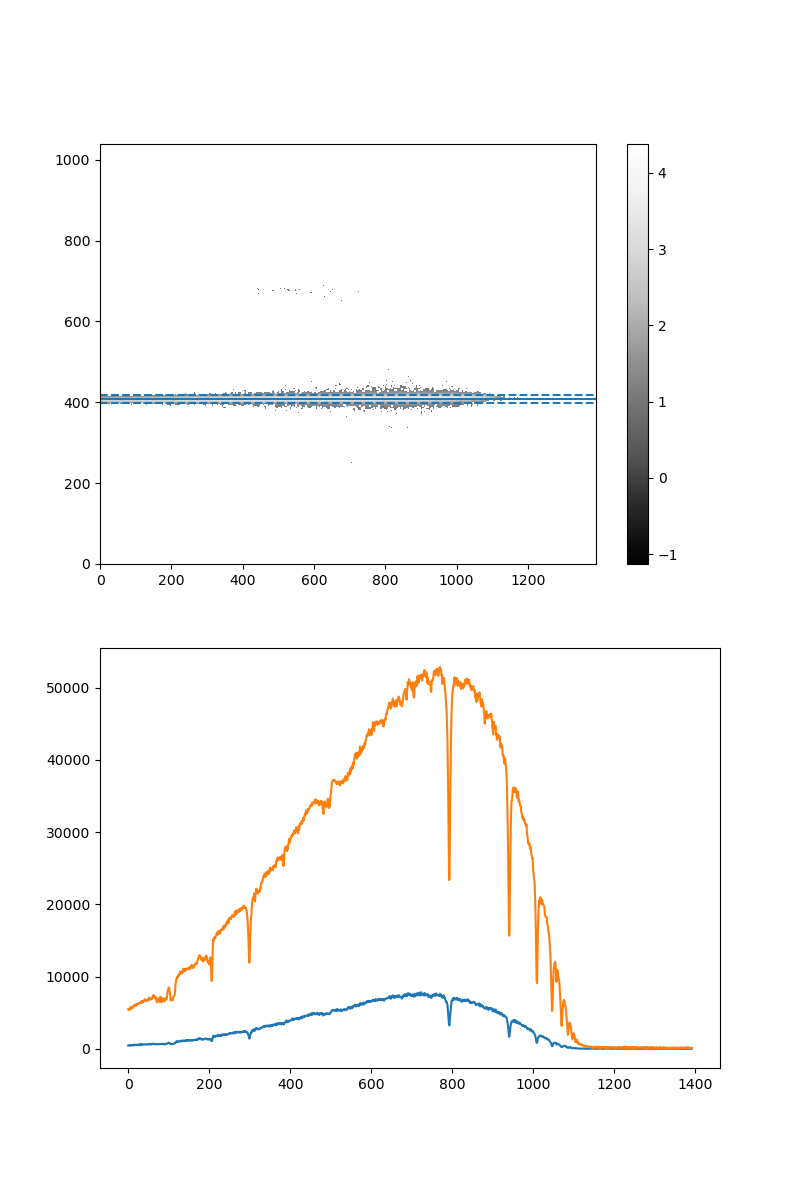

/tmp/ipykernel_18158/3314419943.py:11: RuntimeWarning: divide by zero encountered in log10
  im = ax1.imshow(np.log10(ccd_sci_bg.data), origin='lower',aspect='auto',cmap='Greys_r')
/tmp/ipykernel_18158/3314419943.py:11: RuntimeWarning: invalid value encountered in log10
  im = ax1.imshow(np.log10(ccd_sci_bg.data), origin='lower',aspect='auto',cmap='Greys_r')


(21, 1392)
(1392,)


In [19]:
# In order to use the full information we can sum photons over several lines
## we define the aperture upper/lower limit above/below the central line
ap_l = 10
ap_u = 10

fig = plt.figure(figsize=(8,12))
## overplot extraction zone on the image
ax1 = fig.add_subplot(211)
interval = ZScaleInterval()
z1, z2 = interval.get_limits(ccd_sci_b)
im = ax1.imshow(np.log10(ccd_sci_bg.data), origin='lower',aspect='auto',cmap='Greys_r')
ax1.axhline(i0, ls='-')
ax1.axhline(i0+ap_u, ls='--')
ax1.axhline(i0-ap_l, ls='--')
fig.colorbar(im)

## retrieve the data
print(ccd_sci_bg.data[i0-ap_l:i0+ap_u+1,:].shape)
sci_spec2 = np.sum(ccd_sci_bg.data[i0-ap_l:i0+ap_u+1,:], axis=0)
print(sci_spec2.shape)
ax2 = fig.add_subplot(212)
ax2.plot(sci_spec1)
ax2.plot(sci_spec2)
#ax2.plot(sci_spec1/np.max(sci_spec1))
#ax2.plot(sci_spec2/np.max(sci_spec2))

plt.show()

In [20]:
# ToDo: 
#  * extract the NeAr spectrum using the same extraction zone as for the science spectrum
#  * extract the flat field spectrum using the same extraction zone as for the science spectrum

In [21]:
### Further work: 
###  * compute S/N ratio in the spectrum, taking into account all contributions (photon noise, readout noise, dark current, sky background)
###  * compare NeAr spectrum and subsequent calibration using the same extraction zone as for the science spectrum vs using an extraction zone optimized for NeAr

## Save spectra

In [22]:
# science spectrum
s1d_sci = ccdp.CCDData(data=sci_spec2, meta=ccd_sci.meta, mask=None, unit='electron')
# s1d_sci = ccdp.CCDData(data=sci_spec2, meta=ccd_sci.meta, mask=None, uncertainty=sci_err2, unit='electron')
fname_s1d_sci = os.path.splitext(fname_sci)[0] + '_s1d' + os.path.splitext(fname_sci)[1]
s1d_sci.write('reduced/'+fname_s1d_sci, overwrite=True)

In [23]:
# flat field spectrum
#s1d_flat = ccdp.CCDData(data=flat_spec, meta=master_flat.meta, mask=None, uncertainty=None, unit='adu')
#s1d_flat.write('reference/master_flat_s1d.fits', overwrite=True)

In [24]:
# wavelength calibration spectrum
# s1d_cal = ccdp.CCDData(data=cal_spec, meta=master_cal.meta, mask=None, uncertainty=None, unit='adu')
# s1d_cal.write('reference/master_wcal_s1d.fits', overwrite=True)